# Single Gene Analysis

In [404]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text

## set of features
FEAT_SETS = ["DNA", "Mito", "GFP", "AGP", "Morph"]
## platemaps
PLATEMAP_DIR = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/inputs/metadata/platemaps/{batch_id}/platemap"
## img qc dir
IMG_QC_DIR = "../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/1.image_qc_outputs/{bio_rep}"
## QC-ed PQ files
ALL_PROF_QC = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/batch_profiles/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/batch_profiles/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"
## classification analyses in SM pipeline
SM_CLASS_ANA_DIR = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/classification_analyses"
## classification results in SM pipeline
SM_CLASS_RES_DIR = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/classification_results/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
## classification summary results
CLASS_RES_OUTDIR = "../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/3.classification_results"

In [402]:
BATCH_LIST_DICT = {
    "2024_01_23_Batch_7": "2024_02_Batch_7-8", 
    "2024_02_06_Batch_8": "2024_02_Batch_7-8",
    "2024_12_09_Batch_11": "2024_12_Batch_11-12", 
    "2024_12_09_Batch_12": "2024_12_Batch_11-12",
    "2025_01_27_Batch_13": "2025_01_Batch_13-14", 
    "2025_01_28_Batch_14": "2025_01_Batch_13-14",
    "2025_03_17_Batch_15": "2025_03_Batch_15-16", 
    "2025_03_17_Batch_16": "2025_03_Batch_15-16"
}

BIO_REP_BATCHES_DICT = {
    "2024_01_Batch_7-8": ("2024_01_23_Batch_7", "2024_02_06_Batch_8"),
    "2024_12_Batch_11-12": ("2024_12_09_Batch_11", "2024_12_09_Batch_12"),
    "2025_03_Batch_15-16": ("2025_03_17_Batch_15", "2025_03_17_Batch_16"),
    # "2025_01_Batch_13-14": ("2025_01_27_Batch_13", "2025_01_28_Batch_14")
}

BIO_BATCH_MAP_BIO_REP = {
    "B7A": "2024_01_Batch_7-8",
    "B8A": "2024_01_Batch_7-8",
    "B11A": "2024_12_Batch_11-12",
    "B12A": "2024_12_Batch_11-12",
    "B15A": "2025_03_Batch_15-16",
    "B16A": "2025_03_Batch_15-16",
}

## 1. Loading data

In [390]:
clin_var_df = pl.read_csv(f"../../../../1_allele_collection/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_sequence_confirmed.tsv", 
                          separator="\t", infer_schema_length=10000
).with_columns(
    pl.concat_str([pl.col("symbol"),pl.col("aa_change")], separator="_").alias("gene_allele")
)
imaging_summary = pl.read_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_classification_summary.csv")

## merge the data frames
imaging_summary_clinvar = imaging_summary.join(
    clin_var_df,
    on="gene_allele",
    how="left"
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean").is_null())
    .then(pl.lit("6_No_ClinVar"))
    .otherwise(pl.col("clinvar_clnsig_clean"))
    .alias("clinvar_clnsig_clean")
)
imaging_summary_clinvar.head()

gene_allele,Metadata_Bio_Batch,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_GFP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_GFP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_Mean_Morph,AUROC_Mean_AGP,AUROC_Mean_GFP,AUROC_Mean_Mito,AUROC_Mean_DNA,Altered_95th_perc_Morph,Altered_95th_perc_AGP,Altered_95th_perc_GFP,Altered_95th_perc_Mito,Altered_95th_perc_DNA,Altered_99th_perc_Morph,Altered_99th_perc_AGP,Altered_99th_perc_GFP,Altered_99th_perc_Mito,Altered_99th_perc_DNA,Gene,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,i64,i64,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64
"""KCNJ2_Arg40Gln""","""2025_03_Batch_15-16""",0.972984,0.971045,0.980569,0.97502,0.961829,0.974059,0.981615,0.996136,0.990675,0.960081,0.973521,0.97633,0.988352,0.982847,0.960955,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,"""KCNJ2""","""KCNJ2""","""ENSG00000123700""",100016069,2601,"""CCSBVarC008308""","""ALE00008294""","""NC_000017.11:70175158:G:A""","""119G>A""","""Arg40Gln""",…,"""-""","""RCV000308982|RCV000347359|RCV0…","""MONDO:MONDO:0008222,MedGen:C15…","""Andersen Tawil syndrome|Atrial…","""germline;unknown""","""germline""","""GRCh38""","""NC_000017.11""","""17""",70175158,70175158,"""17q24.3""","""criteria provided, conflicting…",7,"""-""","""N""","""ClinGen:CA8738692""",2,324830,70175158,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000405988|SCV000405989|SCV0…","""-""","""-""","""119G>A ""","""Arg40Gln""","""NM_000891.3""",1,"""3_Conflicting""",0.000029
"""FKBP6_Arg202His""","""2025_03_Batch_15-16""",0.863896,0.869514,0.904622,0.90294,0.809215,0.983654,0.982657,0.941178,0.937145,0.969693,0.923775,0.926086,0.9229,0.920042,0.889454,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,"""FKBP6""","""FKBP6""","""ENSG00000077800""",10177,900211,"""CCSBVarC002929""","""ALE00002929""","""NC_000007.14:73340654:G:A""","""605G>A""","""Arg202His""",…,"""-""","""RCV003974098""","""-""","""FKBP6-related disorder""","""germline""","""germline""","""GRCh38""","""NC_000007.14""","""7""",73340654,73340654,"""7q11.23""","""no assertion criteria provided""",1,"""-""","""N""","""ClinGen:CA4286754""",2,3057196,73340654,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004794340""","""-""","""-""","""605G>A ""","""Arg202His""","""NM_003602.5""",null,"""2_Benign""",0.000887
"""KCNJ2_Ile269Lys""","""2025_03_Batch_15-16""",0.753626,0.960241,0.985371,0.935121,0.809821,0.803822,0.98273,0.993124,0.962842,0.925603,0.778724,0.971485,0.989247,0.948981,0.867712,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,"""KCNJ2""","""KCNJ2""","""ENSG00000123700""",100016069,2637,"""CCSBVarC008339""","""ALE00008325""","""NC_000017.11:70175845:T:A""","""806T>A""","""Ile269Lys""",…,"""-""","""RCV000364962""","""MedGen:CN517202""","""not provided""","""germline""","""germline""","""GRCh38""","""NC_000017.11""","""17""",70175845,70175845,"""17q24.3""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA10603940""",2,281661,70175845,"""T""","""A""","""-""","""-""","""-""","""-""","""-""","""-""",""

In [5]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMG_QC_DIR.format(bio_rep=bio_rep)}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

In [6]:
def plot_gene_level_summary(total_allele_hit_sum_df, cell_change, auroc_thres):
    # 1. Fill nulls with 0
    total_allele_hit_sum_df["len_hits"] = total_allele_hit_sum_df["len_hits"].fillna(0).astype(int)
    # 2. Compute percentage of hits
    total_allele_hit_sum_df["pct_hits"] = total_allele_hit_sum_df["len_hits"] / total_allele_hit_sum_df["len"] * 100
    # 3. Sort by percentage descending
    total_allele_hit_sum_df = total_allele_hit_sum_df.sort_values(by=["len","pct_hits"], ascending=True).reset_index(drop=True)
    
    y = range(len(total_allele_hit_sum_df))
    n_genes = len(y)

    # 4. Dynamically scale figure size
    bar_width = 0.4
    fig_height = max(6, min(n_genes * 0.3, 25))  # cap size for huge plots
    fig_width = 8
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    # Plot bars
    ax.barh(y, total_allele_hit_sum_df["len"], color="skyblue", label="# Variants")
    ax.barh(y, total_allele_hit_sum_df["len_hits"], color="tomato", label="# of Hits")

    # Annotate percentage
    for i, pct in enumerate(total_allele_hit_sum_df["pct_hits"]):
        ax.text(
            total_allele_hit_sum_df.loc[i, "len"] + 0.5,
            i,
            f"{pct:.1f}%",
            ha="left",
            va="center",
            fontsize=10 if n_genes > 20 else 11,
            rotation=0,
        )
    # Axis formatting
    ax.set_yticks(y)
    ax.set_yticklabels(
        total_allele_hit_sum_df["by"],
        fontsize=10 if n_genes > 20 else 11,
    )
    ax.set_xlabel("Count", fontsize=11)
    ax.set_title(
        f"Altered {cell_change.upper()} Hits per Gene (AUROC thres: {auroc_thres})",
        fontsize=13,
    )
    ax.set_xlim(0, total_allele_hit_sum_df["len"].max() * 1.1)
    ax.set_ylim(-1, len(y) + .3)
    ax.legend(fontsize=11, loc="lower right")
    # Improve spacing
    plt.tight_layout()
    plt.show()

    return total_allele_hit_sum_df

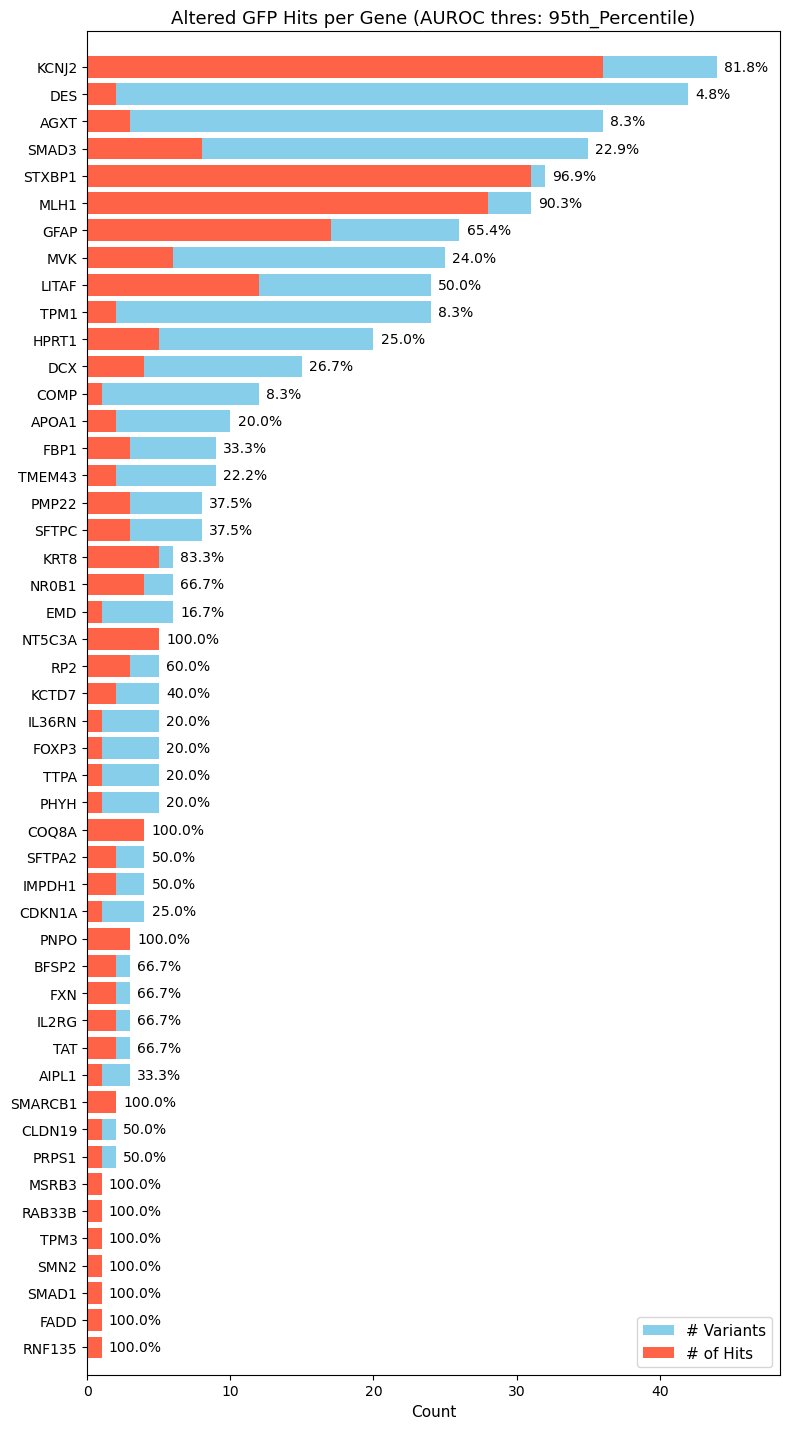

,by,len,len_hits,pct_hits
0,RNF135,1,1,100.0
1,FADD,1,1,100.0
2,SMAD1,1,1,100.0
3,SMN2,1,1,100.0
4,TPM3,1,1,100.0


In [8]:
total_allele_hit_sum_df = imaging_summary_clinvar.group_by("Gene").len().sort(by="len", descending=True).join(
    imaging_summary_clinvar.filter(pl.col(f"Altered_95th_perc_GFP")==1).with_columns(
        pl.col("gene_allele").str.split("_").list.get(0).alias("Gene")
    ).group_by(by="Gene").len().sort(by="len", descending=True),
    left_on="Gene",
    right_on="by",
    suffix="_hits", how="left"
).drop_nulls(subset="len_hits").rename({"Gene":"by"})
total_allele_hit_sum_df = plot_gene_level_summary(total_allele_hit_sum_df.to_pandas(), "GFP", f"{95}th_Percentile")
total_allele_hit_sum_df.head()

## 2. Loading CellProfiler Features

In [ ]:
def remove_corr_feats(df, feat_cols=None, corr_thres=.9):
    if feat_cols is None:
        # 2. Identify numeric columns
        all_num_feats = [
            name
            for name, dtype in df.schema.items()
            if dtype in (pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.Float32, pl.Float64)
        ]
    else:
        all_num_feats = feat_cols
        
    # 3. Bring that slice into pandas
    pdf = df.select(all_num_feats).to_pandas()
    # 4. Compute absolute correlation matrix
    corr = pdf.corr().abs()
    # 5. Mask out the lower triangle (we only need one side)
    upper = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )
    # 6. Pick columns to drop: any column with correlation > threshold to *any* other
    to_drop = [col for col in upper.columns if any(upper[col] > corr_thres)]
    # 7. Drop them in your original Polars DF
    df_drop_corr_cols = df.drop(to_drop)
    # colocal_col_cat = set(["_".join(col.split('_')[1:3]) for col in colocal_cols])
    # print(colocal_col_cat)
    # colocal_col_dict = defaultdict(list)
    # for col in colocal_cols:
    #     colocal_col_dict["_".join(col.split('_')[1:3])].append(col)
    # colocal_col_dict
    return df_drop_corr_cols


def inverse_normal_transform(data, feat_cols=None):
    """
    Apply inverse normal transformation (rank-based normalization) to data.
    """
    from scipy.stats import norm
    from scipy.stats import rankdata
    
    def transform_column_polars(col_name, df):
        """Transform a polars column"""
        return (
            pl.when(pl.col(col_name).is_not_null())
            .then(
                pl.col(col_name)
                .rank(method="average")
                .sub(0.5)
                .truediv(pl.col(col_name).drop_nulls().len())
                .map_elements(lambda x: norm.ppf(x), return_dtype=pl.Float64)
            )
            .otherwise(pl.col(col_name))
            .alias(col_name)
        )

    if feat_cols is None:
        numeric_cols = [
            col 
            for col in data.columns 
            if data[col].dtype in [pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64]
        ]
    else:
        numeric_cols = feat_cols
        
    # Polars DataFrame
    
    # Apply transformation to numeric columns only
    transformations = [transform_column_polars(col, data) for col in numeric_cols]
    non_numeric_cols = [col for col in data.columns if col not in numeric_cols]
    
    if transformations:
        if non_numeric_cols:
            # Keep non-numeric columns as they are
            return data.with_columns(transformations).select(data.columns)
        else:
            return data.with_columns(transformations)
    else:
        return data  # No numeric columns to transform

In [363]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, optimal_leaf_ordering
from scipy.spatial.distance import squareform, pdist
from sklearn.preprocessing import StandardScaler
from matplotlib import colormaps
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap


def find_optimal_clusters_pdist(data, distance_vector, linkage_matrix, min_k, max_k):
    """Find optimal number of clusters using multiple criteria with precomputed distances."""
    from sklearn.metrics import silhouette_score, calinski_harabasz_score
    scores = {
        'silhouette': [],
        'calinski_harabasz': []
    }
    k_range = range(min_k, min(max_k + 1, len(data)))
    for k in k_range:
        labels = fcluster(linkage_matrix, k, criterion='maxclust')
        try:
            # Silhouette score using precomputed distances
            distance_matrix = squareform(distance_vector)
            sil_score = silhouette_score(distance_matrix, labels, metric='precomputed')
            scores['silhouette'].append(sil_score)
            
            # Calinski-Harabasz score (higher is better)
            ch_score = calinski_harabasz_score(data, labels)
            scores['calinski_harabasz'].append(ch_score)
        except:
            scores['silhouette'].append(-1)
            scores['calinski_harabasz'].append(0)
    
    # Find optimal k based on silhouette score
    if scores['silhouette'] and max(scores['silhouette']) > -1:
        optimal_k = k_range[np.argmax(scores['silhouette'])]
    else:
        optimal_k = min_k
    return optimal_k
    

def robust_cosine_clustering_with_annotations(df, 
                                              feature_cols,
                                              annotation_cols,
                                              continuous_annotations,
                                              n_clusters=None, 
                                              method='average', 
                                              min_clusters=2, 
                                              max_clusters=20,
                                              optimal_ordering=True):
    """
    Perform robust clustering using cosine similarities with categorical and continuous annotations.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Feature matrix with annotations (features/annotations x samples)
    feature_cols : list, optional
        List of col names to use for clustering. If None, will exclude annotation rows
    annotation_cols : list, optional
        List of categorical annotation col names (e.g., ["clinvar_clnsig_clean", "Altered_95th_perc_GFP"])
    continuous_annotations : list, optional
        List of continuous annotation row names (e.g., ["AUROC"])
    n_clusters : int, optional
        Number of clusters. If None, will be determined automatically
    method : str
        Linkage method for hierarchical clustering
    standardize : bool
        Whether to standardize features before clustering
    optimal_ordering : bool
        Whether to use optimal leaf ordering
    
    Returns:
    --------
    dict with clustering results and validation metrics
    """
    # Extract feature data for clustering
    data = df[feature_cols].astype(float)
    
    # Step 2: Compute cosine distance between columns (samples)
    # Transpose to cluster columns (samples) -> shape (n_samples, n_features)    
    # Compute cosine distance between samples
    cosine_dist = pdist(data, metric='cosine')
    
    # Step 3: Perform hierarchical clustering
    linkage_matrix = linkage(cosine_dist, method=method)
    
    # Step 4: Optimal leaf ordering to minimize distance jumps
    if optimal_ordering:
        opt_linkage = optimal_leaf_ordering(linkage_matrix, cosine_dist)
    else:
        opt_linkage = linkage_matrix
    
    # Step 5: Determine optimal number of clusters if not specified
    if n_clusters is None:
        n_clusters = find_optimal_clusters_pdist(
            data, cosine_dist, linkage_matrix, 
            min_clusters, max_clusters
        )
    
    # Step 6: Get cluster labels
    cluster_labels = fcluster(opt_linkage, n_clusters, criterion='maxclust')
    
    # Create cluster labels for samples
    sample_cluster_df = pd.DataFrame({
        'Sample': data.index,
        'Cluster': cluster_labels
    }).set_index('Sample')
    
    # Step 7: Create results dictionary
    results = {
        'data': df[feature_cols],
        'cluster_labels': cluster_labels,
        'n_clusters': n_clusters,
        'linkage_matrix': opt_linkage,
        'linkage_method': method,
        'feature_cols': feature_cols,
        'annotation_cols': annotation_cols,
        'continuous_annotations': continuous_annotations,
        'sample_clusters': sample_cluster_df,
    }
    return results


def create_column_colors_dataframe(df, clustering_results, palettes):
    """Create a DataFrame with column colors for all annotations and clusters."""
    annotation_cols = clustering_results['annotation_cols']
    continuous_annotations = clustering_results['continuous_annotations']
    sample_clusters = clustering_results['sample_clusters']
    
    col_colors_dict = {}
    palette_map = 2 * [sns.color_palette("husl"), sns.color_palette("hls"), sns.color_palette("tab10"), sns.color_palette("muted"), sns.color_palette("colorblind")]
    # Add categorical annotations
    for i, ann_col in enumerate(annotation_cols):
        if ann_col in df.columns:
            if ann_col in palettes:
                col_colors_dict[ann_col] = df[ann_col].map(palettes[ann_col])
            else:
                ann_elements = df[ann_col].unique()
                palettes[ann_col] = dict(zip(ann_elements, palette_map[i][:len(ann_elements)]))
                col_colors_dict[ann_col] = df[ann_col].map(palettes[ann_col])
                
    # Add cluster colors
    cluster_series = pd.Series(clustering_results['cluster_labels'], 
                               index=df.index)
    cluster_set = sorted(set(clustering_results['cluster_labels']))
    # display(cluster_series.sort_values())
    palettes['Cluster'] = dict(zip(cluster_set, sns.color_palette("husl", len(cluster_set))))
    col_colors_dict['Cluster'] = cluster_series.map(palettes['Cluster'])
    
    # Add continuous annotations (normalized to [0,1] for colormap)
    for cont_ann in continuous_annotations:
        if cont_ann in df.columns:
            values = df[cont_ann].astype(float)
            # Normalize values to [0,1]
            normalized_values = (values - values.min()) / (values.max() - values.min())
            # Apply colormap
            cmap = colormaps.get_cmap("viridis_r") #plt.cm.get_cmap("")
            col_colors_dict[cont_ann] = [cmap(val) for val in normalized_values]
    
    # Create DataFrame
    col_colors_df = pd.DataFrame(col_colors_dict, index=df.index)
    return col_colors_df, palettes
    

def create_comprehensive_clustermap(df, clustering_results, label,
                                    cmap='vlag', 
                                    save_path=None, show_legends=True):
    """
    Create a comprehensive clustermap with all annotations and cluster information.
    """
    
    # Get the clustering data
    data = clustering_results['data']
    linkage_matrix = clustering_results['linkage_matrix']

    clinvar_palette_set2 = sns.color_palette("Set2")
    clinvar_palette_set2[0], clinvar_palette_set2[1], clinvar_palette_set2[2], clinvar_palette_set2[3], clinvar_palette_set2[4], clinvar_palette_set2[5], clinvar_palette_set2[7] = \
    clinvar_palette_set2[1], clinvar_palette_set2[4], clinvar_palette_set2[3], clinvar_palette_set2[2], clinvar_palette_set2[0], clinvar_palette_set2[7], clinvar_palette_set2[5]
    clinvar_category = ['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others', '6_No_ClinVar']
    palettes = {
        "clinvar_clnsig_clean": dict(zip(clinvar_category, clinvar_palette_set2[:7]))
    }

    # Create column colors DataFrame
    col_colors_df, palettes = create_column_colors_dataframe(
        df, clustering_results, palettes
    )

    figsize = (data.shape[1] // 3, data.shape[1] // 3)
    ## Create the clustermap
    g = sns.clustermap(
        data.T,
        col_linkage=linkage_matrix,
        col_colors=col_colors_df,
        cmap=cmap,
        cbar_pos=(-.05, .3, .02, .25),
        cbar_kws={'label': "Normalized CP Feature"},
        figsize=figsize,
        linewidths=0.01,
        row_cluster=True,  # Also cluster features
        xticklabels=True,  # Hide sample labels for cleaner look
        yticklabels=True
    )
    
    # Customize the plot
    g.ax_heatmap.set_xlabel('Samples (Clustered)', fontsize=12)
    g.ax_heatmap.set_ylabel('Features', fontsize=12)
    # g.ax_cbar.tick_params(axis='x', length=10)
    
    # Add legends if requested
    if show_legends:
        # Calculate number of columns for horizontal legend layout
        n_legends = len([name for name in palettes.keys() 
                        if name in clustering_results['annotation_cols'] or name == 'Cluster'])
        n_cols = 5  # Max 3 columns
        
        # Position legends horizontally below the plot
        legend_y = .95
        legend_x_start = 0.75
        legend_x_spacing = 0.15
        for i, (ann_name, palette) in enumerate(palettes.items()):
            if ann_name in clustering_results['annotation_cols'] or ann_name == 'Cluster':
                handles = [mpatches.Patch(color=color, label=label) 
                          for label, color in palette.items()]
                col = i % n_cols
                row = i // n_cols
                legend = g.fig.legend(handles=handles, title=ann_name,
                                      bbox_to_anchor=(legend_x_start - col * legend_x_spacing, legend_y - row * 0.1),
                                      loc='upper right',
                                      ncol=1,
                                      frameon=True)
                legend.set_title(ann_name, prop={'weight': 'bold', 'size': 10})
        
        # # Add continuous annotation info
        # cont_info = []
        # for cont_ann in clustering_results['continuous_annotations']:
        #     if cont_ann in df.columns:
        #         values = df[cont_ann].astype(float)
        #         cont_info.append(f"{cont_ann}: {values.min():.2f}-{values.max():.2f}")
        
        # if cont_info:
        #     g.fig.text(0.1, legend_y - 0.25, "Continuous annotations: " + ", ".join(cont_info), 
        #               fontsize=10, style='italic')
    
    # Adjust layout to make room for legends
    # plt.subplots_adjust(right=0.85)  # Make room on the right for legends
    plt.suptitle(f'Comprehensive Variant Clustering Analysis\n'
                f'Method: {clustering_results["linkage_method"]}, '
                f'Clusters: {clustering_results["n_clusters"]}, '
                f'Features: {len(clustering_results["feature_cols"])}', 
                y=1.02, fontsize=14, weight='bold')
    plt.show()

    # ----------------------------
    # 4. Compute UMAP Projection and Plot the Clusters
    # ----------------------------
    np.random.seed(0)
    umap_reducer = umap.UMAP(random_state=0, n_jobs=1)
    embedding = umap_reducer.fit_transform(clustering_results["data"])
    umap_df = pd.DataFrame({
        'UMAP-1': embedding[:, 0],
        'UMAP-2': embedding[:, 1],
        'Cluster': clustering_results["cluster_labels"],
        'Mislocalization': df["Mislocalized"].values
    }, index=results["data"].index)

    display(umap_df)
    fig, ax = plt.subplots(1,1,figsize=(7, 6))
    sns.scatterplot(x='UMAP-1', y='UMAP-2', hue='Cluster', ax=ax, style="Mislocalization",
                    palette=palettes["Cluster"], data=umap_df, s=40, edgecolor='k')
    texts = []
    for i, label in enumerate(list(df.index)):
        texts.append(ax.text(umap_df.iloc[i, 0], umap_df.iloc[i, 1], label, 
                     fontsize=9, fontweight='bold', color='black'))
    adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax)
    
    ax.set_title("UMAP Projection with Hierarchical Clusters")
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.legend(title='')
    plt.tight_layout()
    plt.show()
    
    if save_path:
        g.savefig(f"{save_path}/clustering_{label}.png", dpi=400)
        fig.savefig(f"{save_path}/umap_{label}.png", dpi=400, bbox_inches='tight')
    return g, palettes

In [392]:
gene = "MLH1"
feat = "GFP"

In [398]:
gene_variant_scores = imaging_summary_clinvar.filter(pl.col("gene_allele").str.contains(gene))
variant_list = list(gene_variant_scores["gene_allele"]) + [gene]
bio_reps = list(gene_variant_scores["Metadata_Bio_Batch"].unique())
gene_variant_scores["Metadata_Bio_Batch"].unique()

Metadata_Bio_Batch
str
"""2024_12_Batch_11-12"""


In [399]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(variant_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        feat_cols = [col for col in batch_alleles.columns if feat.lower() in col.lower()]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==feat).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(meta_cols+feat_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

In [406]:
# Paths
ref_var_cell_all_prof_list = []
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                ALL_PROF_QC.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(variant_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        )
        ref_var_cell_all_prof_list.append(batch_alleles)

# all_feat_cols = [i for i in ref_var_cell_all_prof_list[0].collect_schema() if feat.lower() in i.lower() and "Brightfield" not in i]
all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if feat.lower() in col.lower() and "Brightfield" not in col] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
select_cols = list(all_feat_cols) + ["Metadata_CellID"]
ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])
# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
                                                        on="Metadata_CellID", how="left", coalesce=True)

In [391]:
# def plot_top_n_important_feat(df, feat_cols, n=10, ax=None, title=""):
#     # Calculate mean and standard deviation for each column
#     column_stats = df[feat_cols].agg(['mean', 'std']).T

#     # Sort columns by the sum of mean and std in descending order
#     sorted_columns = column_stats.sort_values(by=["mean"], ascending=False)
#     sorted_columns = sorted_columns.head(n)
#     # display(sorted_columns)

#     # Plot mean and std for each column
#     if ax is None:
#         fig, ax = plt.subplots(figsize=(5, 4))
#     ax.barh(y=sorted_columns.index, width=sorted_columns["mean"], color='skyblue') ## yerr=sorted_columns["std"], capsize=5, edgecolor='black'
#     ax.set_yticks(range(len(sorted_columns.index)))
#     ax.set_yticklabels(sorted_columns.index, rotation=0, fontsize=10)
#     # ax.set_xlabel("Mean")
#     ax.set_title(f"Features Importance Mean {title}")
#     ax.axvline(x=0.01, color='r', linestyle='--')
#     # plt.tight_layout()
#     # plt.show()
#     return sorted_columns

# feat_import_df_feat = pl.DataFrame()
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     for batch_id in bio_rep_batches:
#         # Read the data
#         feat_df = pl.read_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
#         meta_cols = [c for c in feat_df.columns if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
#         feat_cols = [c for c in feat_df.columns if c not in meta_cols]
#         feat_df = feat_df.with_columns([
#             pl.col(c).cast(pl.Float64) for c in feat_cols
#         ])
#         feat_df = feat_df.with_columns(
#             pl.lit(batch_id).alias("Metadata_Batch"),
#             pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
#         )
#         if feat != "Morph":
#             feat_cols = [
#                 i
#                 for i in feat_cols
#                 if (feat.lower() in i.lower())
#                 and ("Brightfield" not in i) ## excluding Brightfield features
#             ]
#         else:
#             feat_cols = [
#                 i
#                 for i in feat_cols
#                 if ("GFP" not in i) and ("Brightfield" not in i)
#             ]
#         feat_df_batch = feat_df.filter(
#             (pl.col("Metadata_Feature_Type")==feat)&(~pl.col("Metadata_Control"))&(pl.col("Group1").is_in(variant_list)|(pl.col("Metadata_gene_allele").is_in(variant_list)))
#         ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
#         feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch], how="diagonal")
        
# for batch in feat_import_df_feat.filter(pl.col("Metadata_gene_allele")=="MVK_Pro288Leu").unique("Metadata_Batch")["Metadata_Batch"]:
#     batch_df = feat_import_df_feat.filter(pl.col("Metadata_Batch")==batch)
#     non_null_gfp = [col for col in batch_df.columns if not batch_df[col].is_null().any() and "GFP" in col]
#     batch_df_col = plot_top_n_important_feat(batch_df.to_pandas(), non_null_gfp, title=batch)

In [411]:
ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
    pl.col("Metadata_Plate")
      # capture a “B” followed by any non-underscore chars up to the first “A”
      .str.extract(r"(B[^_]*?A)", 1)
      .alias("Metadata_Batch")
).with_columns(
    pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_BIO_REP).alias("Metadata_Bio_Batch")
)

ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
    "Metadata_gene_allele", "Metadata_Bio_Batch"
).agg(
    pl.col(col).median().alias(col)
    for col in all_feat_cols
    if not col.startswith("Metadata_")
).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"])

non_null_cols_batch = [col for col in ref_var_allele_batch_all_prof_df.columns if not ref_var_allele_batch_all_prof_df[col].is_null().any() and "Metadata" not in col]
var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
    var_allele_meta_cols+non_null_cols_batch
)
# ref_var_allele_batch_all_prof_df

In [412]:
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_all_prof_df)
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_proc_prof_df)

non_null_cols_batch = [col for col in ref_var_allele_batch_proc_prof_df.columns if not ref_var_allele_batch_proc_prof_df[col].is_null().any() and "Metadata" not in col]
ref_var_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.select(
    var_allele_meta_cols + [col for col in non_null_cols_batch if ref_var_allele_batch_all_prof_df.select(pl.col(col).std()).item() != 0]
)

var_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.join(
    gene_variant_scores.select(
        [
            "gene_allele", "Metadata_Bio_Batch",
            "Altered_95th_perc_GFP", "clinvar_clnsig_clean", "AUROC_Mean_GFP"
        ]
    ), 
    left_on=["Metadata_gene_allele", "Metadata_Bio_Batch"],
    right_on=["gene_allele", "Metadata_Bio_Batch"],
    how="inner"
).with_columns(
    pl.col("Altered_95th_perc_GFP").cast(pl.Boolean).alias("Mislocalized")
)

ref_allele_batch_proc_prof_df = ref_var_allele_batch_proc_prof_df.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).group_by(
    "Metadata_gene_allele", "Metadata_Bio_Batch"
).agg(
    pl.col(col).median().alias(col)
    for col in ref_var_allele_batch_proc_prof_df.columns
    if not col.startswith("Metadata_")
)

ref_var_allele_batch_proc_prof_df = pl.concat([
    var_allele_batch_proc_prof_df,
    ref_allele_batch_proc_prof_df,
], how="diagonal").with_columns(
    pl.col("Mislocalized").fill_null(False),
    pl.col("clinvar_clnsig_clean").fill_null("6_No_ClinVar"),
    pl.col("AUROC_Mean_GFP").fill_null(0)
)

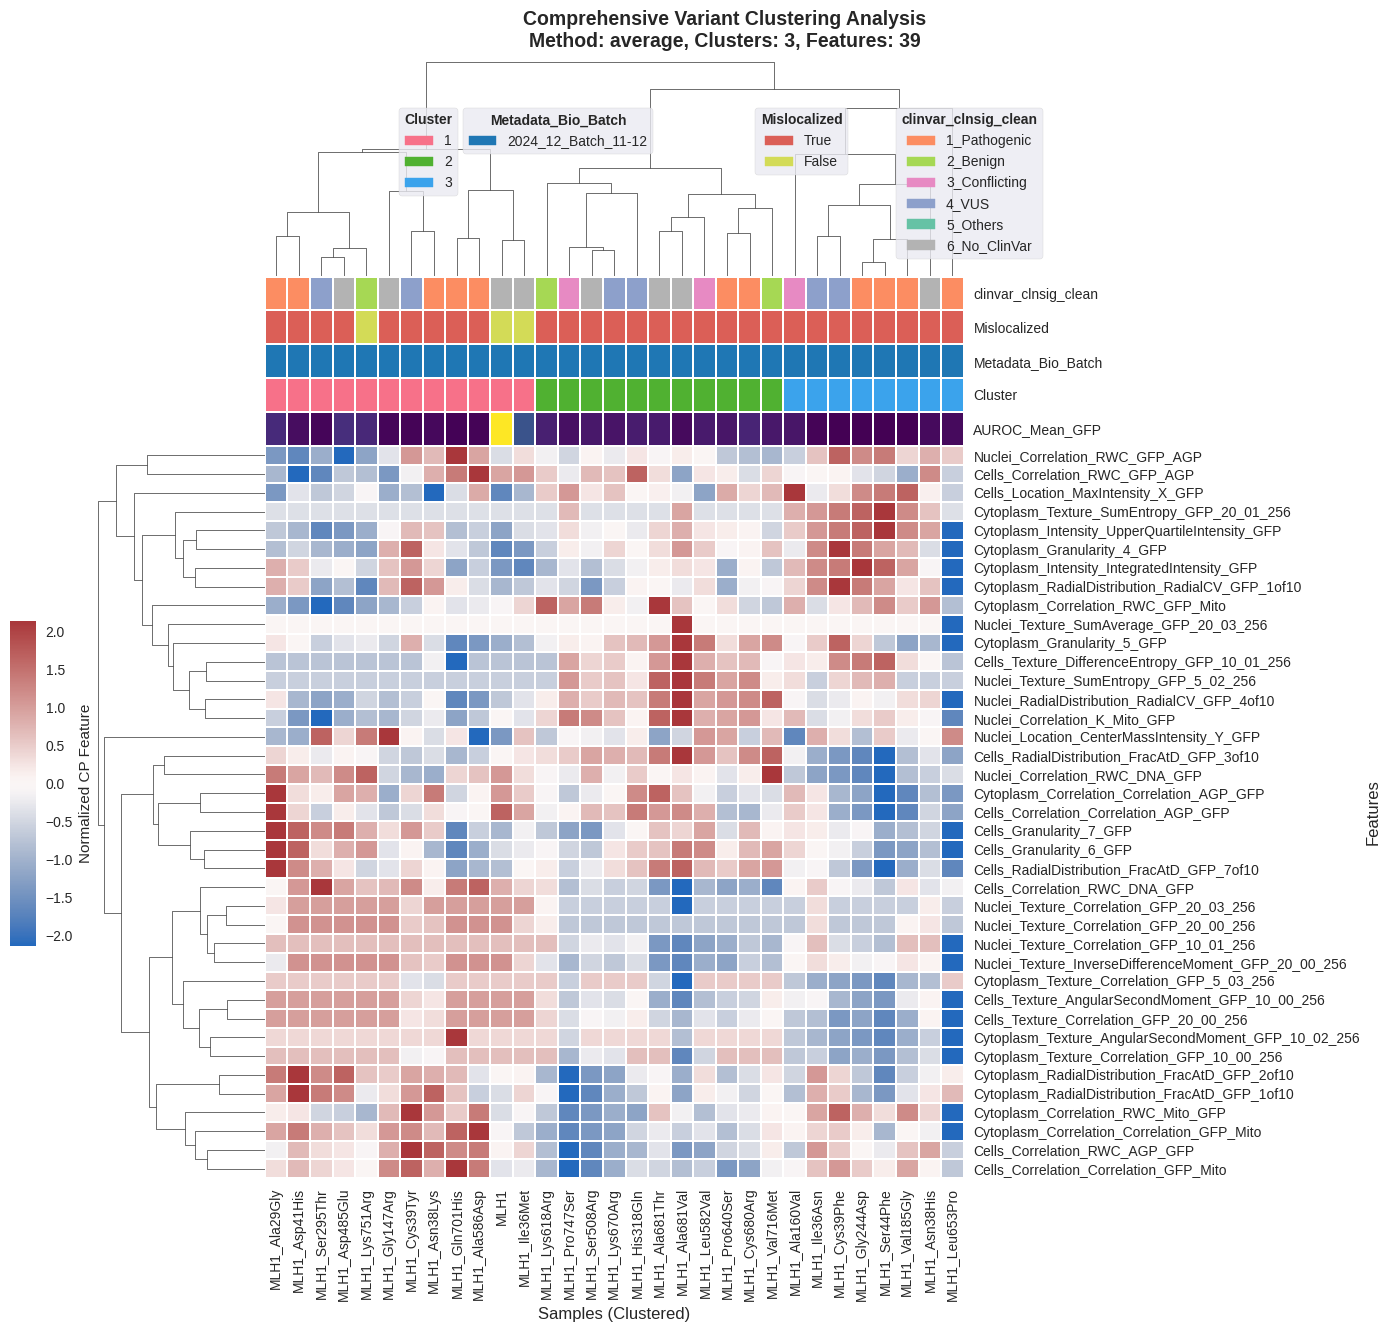

,UMAP-1,UMAP-2,Cluster,Mislocalization
Metadata_gene_allele,,,,
MLH1_Cys39Phe,6.858058,9.829368,3,True
MLH1_Asp41His,9.664775,9.564018,1,True
MLH1_Leu653Pro,7.996836,12.375931,3,True
MLH1_Gln701His,8.590669,10.387565,1,True
MLH1_Val716Met,6.919885,12.873693,2,True
MLH1_Ser295Thr,9.096065,9.564524,1,True
MLH1_Lys670Arg,6.693475,12.077733,2,True
MLH1_Cys680Arg,6.485419,12.378915,2,True
MLH1_His318Gln,7.173615,11.890643,2,True


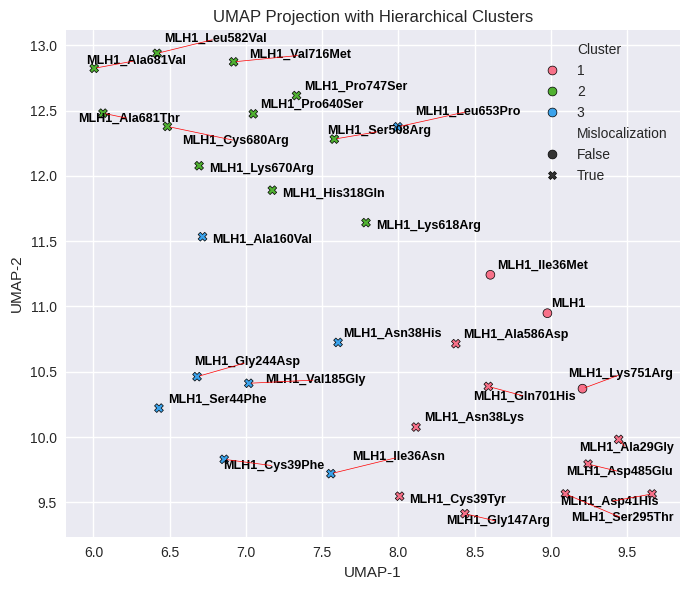

In [413]:
results = robust_cosine_clustering_with_annotations(ref_var_allele_batch_proc_prof_df.to_pandas().set_index("Metadata_gene_allele"),
                                                    feature_cols=[col for col in non_null_cols_batch if col in ref_var_allele_batch_proc_prof_df.columns],
                                                    annotation_cols=["clinvar_clnsig_clean", "Mislocalized", "Metadata_Bio_Batch"],
                                                    continuous_annotations=["AUROC_Mean_GFP"])
clustermap = create_comprehensive_clustermap(ref_var_allele_batch_proc_prof_df.to_pandas().set_index("Metadata_gene_allele"), 
                                             results, 
                                             label="cp_feat",
                                             save_path="/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP_imgs")

### WRT to Ref

In [414]:
## Normalize var per batch
var_allele_prof_wrt_ref_df = pl.DataFrame()
for batch in ref_var_allele_batch_all_prof_df["Metadata_Bio_Batch"].unique():
    ref_var_allele_all_prof_batch = ref_var_allele_batch_all_prof_df.filter(
        pl.col("Metadata_Bio_Batch")==batch
    )
    batch_feat_cols = [col for col in ref_var_allele_all_prof_batch.columns if "Metadata" not in col]
    ## INT normalization per batch
    ref_var_allele_all_prof_batch = inverse_normal_transform(ref_var_allele_all_prof_batch)
    batch_ref = ref_var_allele_all_prof_batch.filter(
        (~pl.col("Metadata_gene_allele").str.contains("_"))
    ).to_pandas().set_index("Metadata_gene_allele")[batch_feat_cols]
    # display(batch_ref)
    batch_var = ref_var_allele_all_prof_batch.filter(
        (pl.col("Metadata_gene_allele").str.contains("_"))
    ).to_pandas().set_index("Metadata_gene_allele")[batch_feat_cols]
    # display(batch_var)
    batch_var = batch_var - batch_ref.loc[gene]
    # display(batch_var)
    var_allele_prof_wrt_ref_df = pl.concat([
        var_allele_prof_wrt_ref_df, 
        pl.DataFrame(
            batch_var.reset_index()
        ).with_columns(
            pl.lit(batch).alias("Metadata_Bio_Batch")
        )
    ])

In [415]:
var_allele_prof_wrt_ref_df = remove_corr_feats(var_allele_prof_wrt_ref_df)
non_null_cols_batch = [col for col in var_allele_prof_wrt_ref_df.columns if not var_allele_prof_wrt_ref_df[col].is_null().any() and "Metadata" not in col]
var_allele_meta_cols = [col for col in var_allele_prof_wrt_ref_df.columns if "Metadata" in col]
var_allele_prof_wrt_ref_df = var_allele_prof_wrt_ref_df.select(
    var_allele_meta_cols + [col for col in non_null_cols_batch if var_allele_prof_wrt_ref_df.select(pl.col(col).std()).item() != 0]
)

In [416]:
var_allele_prof_wrt_ref_df = var_allele_prof_wrt_ref_df.join(
    gene_variant_scores.select(
        [
            "gene_allele", "Metadata_Bio_Batch",
            "Altered_95th_perc_GFP", "clinvar_clnsig_clean", "AUROC_Mean_GFP"
        ]
    ), 
    left_on=["Metadata_gene_allele", "Metadata_Bio_Batch"],
    right_on=["gene_allele", "Metadata_Bio_Batch"],
    how="inner"
).with_columns(
    pl.col("Altered_95th_perc_GFP").cast(pl.Boolean).alias("Mislocalized")
)

In [417]:
var_allele_prof_wrt_ref_df.unique("Altered_95th_perc_GFP")

Metadata_gene_allele,Metadata_Bio_Batch,Cells_Texture_DifferenceEntropy_GFP_10_01_256,Cells_Location_MaxIntensity_X_GFP,Cytoplasm_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_10_01_256,Cells_RadialDistribution_FracAtD_GFP_3of10,Cytoplasm_Texture_AngularSecondMoment_GFP_10_02_256,Nuclei_Correlation_Correlation_AGP_GFP,Cytoplasm_Intensity_UpperQuartileIntensity_GFP,Cytoplasm_Texture_InfoMeas1_GFP_5_02_256,Nuclei_Correlation_RWC_GFP_AGP,Nuclei_Texture_SumEntropy_GFP_5_02_256,Cells_Texture_AngularSecondMoment_GFP_10_00_256,Nuclei_Texture_SumAverage_GFP_20_03_256,Nuclei_RadialDistribution_RadialCV_GFP_4of10,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cells_Granularity_3_GFP,Cells_Granularity_6_GFP,Cytoplasm_Intensity_IntegratedIntensity_GFP,Nuclei_Correlation_RWC_DNA_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_2of10,Cytoplasm_Correlation_RWC_Mito_GFP,Nuclei_Correlation_RWC_Mito_GFP,Cells_Texture_Correlation_GFP_5_02_256,Cells_Intensity_IntegratedIntensity_GFP,Nuclei_Texture_SumAverage_GFP_20_02_256,Nuclei_Location_CenterMassIntensity_Y_GFP,Cytoplasm_Correlation_RWC_GFP_Mito,Cytoplasm_Granularity_2_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_Correlation_GFP_5_03_256,Cytoplasm_Granularity_4_GFP,Cells_Correlation_RWC_GFP_AGP,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_Correlation_RWC_AGP_GFP,Cytoplasm_Granularity_3_GFP,Cytoplasm_Correlation_Correlation_AGP_GFP,Cells_Correlation_RWC_DNA_GFP,Cytoplasm_Granularity_5_GFP,Cells_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_RWC_GFP_AGP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cells_Granularity_7_GFP,Cells_Correlation_Correlation_GFP_Mito,Altered_95th_perc_GFP,clinvar_clnsig_clean,AUROC_Mean_GFP,Mislocalized
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,bool
"""MLH1_Asn38Lys""","""2024_12_Batch_11-12""",0.590299,-0.480501,0.0,0.0,-0.415987,0.0,0.519231,1.811411,0.0,1.116077,0.0,-0.744162,0.0,0.70009,-0.730271,-0.370799,-0.509257,1.816732,-2.114828,0.807541,1.473401,1.116077,-0.844297,1.400745,0.762815,0.984758,0.161895,2.741377,-1.982659,0.0,-0.921921,1.905704,-0.117704,1.982659,1.57975,2.260876,0.343331,-0.645112,0.641427,-1.331406,0.762815,0.781038,1.431178,1.136832,1.0,"""1_Pathogenic""",0.978019,true
"""MLH1_Ile36Met""","""2024_12_Batch_11-12""",0.0,0.735453,0.0,0.0,0.245006,0.0,-0.080947,0.795245,0.0,0.745279,0.0,0.0,0.0,0.370799,0.0,0.166862,0.170981,-0.259953,-0.728123,0.080947,0.33504,0.945096,0.0,0.189513,0.0,2.000924,0.496935,1.083784,-1.341232,0.0,0.0,0.259953,0.13217,0.225154,0.33504,0.449465,-0.551481,-0.391554,0.249873,-0.735453,1.431178,-0.619143,0.762815,0.084285,0.0,"""6_No_ClinVar""",0.743273,false


In [426]:
gene_variant_scores

gene_allele,Metadata_Bio_Batch,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_GFP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_GFP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_Mean_Morph,AUROC_Mean_AGP,AUROC_Mean_GFP,AUROC_Mean_Mito,AUROC_Mean_DNA,Altered_95th_perc_Morph,Altered_95th_perc_AGP,Altered_95th_perc_GFP,Altered_95th_perc_Mito,Altered_95th_perc_DNA,Altered_99th_perc_Morph,Altered_99th_perc_AGP,Altered_99th_perc_GFP,Altered_99th_perc_Mito,Altered_99th_perc_DNA,Gene,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,i64,i64,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,i64,i64,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64
"""MLH1_Ile36Met""","""2024_12_Batch_11-12""",0.741713,0.709684,0.742591,0.691992,0.788203,0.750546,0.725388,0.743955,0.74579,0.723637,0.746129,0.717536,0.743273,0.718891,0.75592,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""MLH1""",null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""6_No_ClinVar""",null
"""MLH1_Asn38Lys""","""2024_12_Batch_11-12""",0.92188,0.969098,0.984143,0.954767,0.964986,0.535587,0.895905,0.971894,0.873984,0.926607,0.728734,0.932501,0.978019,0.914376,0.945797,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,"""MLH1""","""MLH1""","""ENSG00000076242""",2713,470,"""CCSBVarC007375""","""ALE00007363""","""NC_000003.12:36993661:C:G""","""114C>G""","""Asn38Lys""",…,"""-""","""RCV000075121|RCV001176886|RCV0…","""MONDO:MONDO:0005835,MedGen:C45…","""Lynch syndrome|Hereditary canc…","""germline;unknown""","""germline""","""GRCh38""","""NC_000003.12""","""3""",36993661,36993661,"""3p22.2""","""reviewed by expert panel""",5,"""ACMG2013,ACMG2016,ACMG2021,ACM…","""N""","""ClinGen:CA004476,UniProtKB:P40…",2,89651,36993661,"""C""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000106112""","""-""","""-""","""114C>G ""","""Asn38Lys""","""NM_000249.4""",3,"""1_Pathogenic""",null
"""MLH1_Ala681Val""","""2024_12_Batch_11-12""",0.882216,0.968657,0.978129,0.89231,0.96207,0.925994,0.967736,0.96875,0.942328,0.956576,0.904105,0.968196,0.973439,0.917319,0.959323,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,"""MLH1""",null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""6_No_ClinVar""",null
"""MLH1_Gly147Arg""","""2024_12_Batch_11-12""",0.909733,0.951746,0.985722,0.96911,0.968353,0.894305,0.916729,0.984422,0.949844,0.971986,0.902019,0.934237,0.985072,0.959477,0.97017,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,"""MLH1""",null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""6_No_ClinVar""",null
"""MLH1_Ser44Phe""","""2024_12_Batch_11-12""",0.976569,0.996798,0.998808,0.991663,0.998402,0.954752,0.991489,

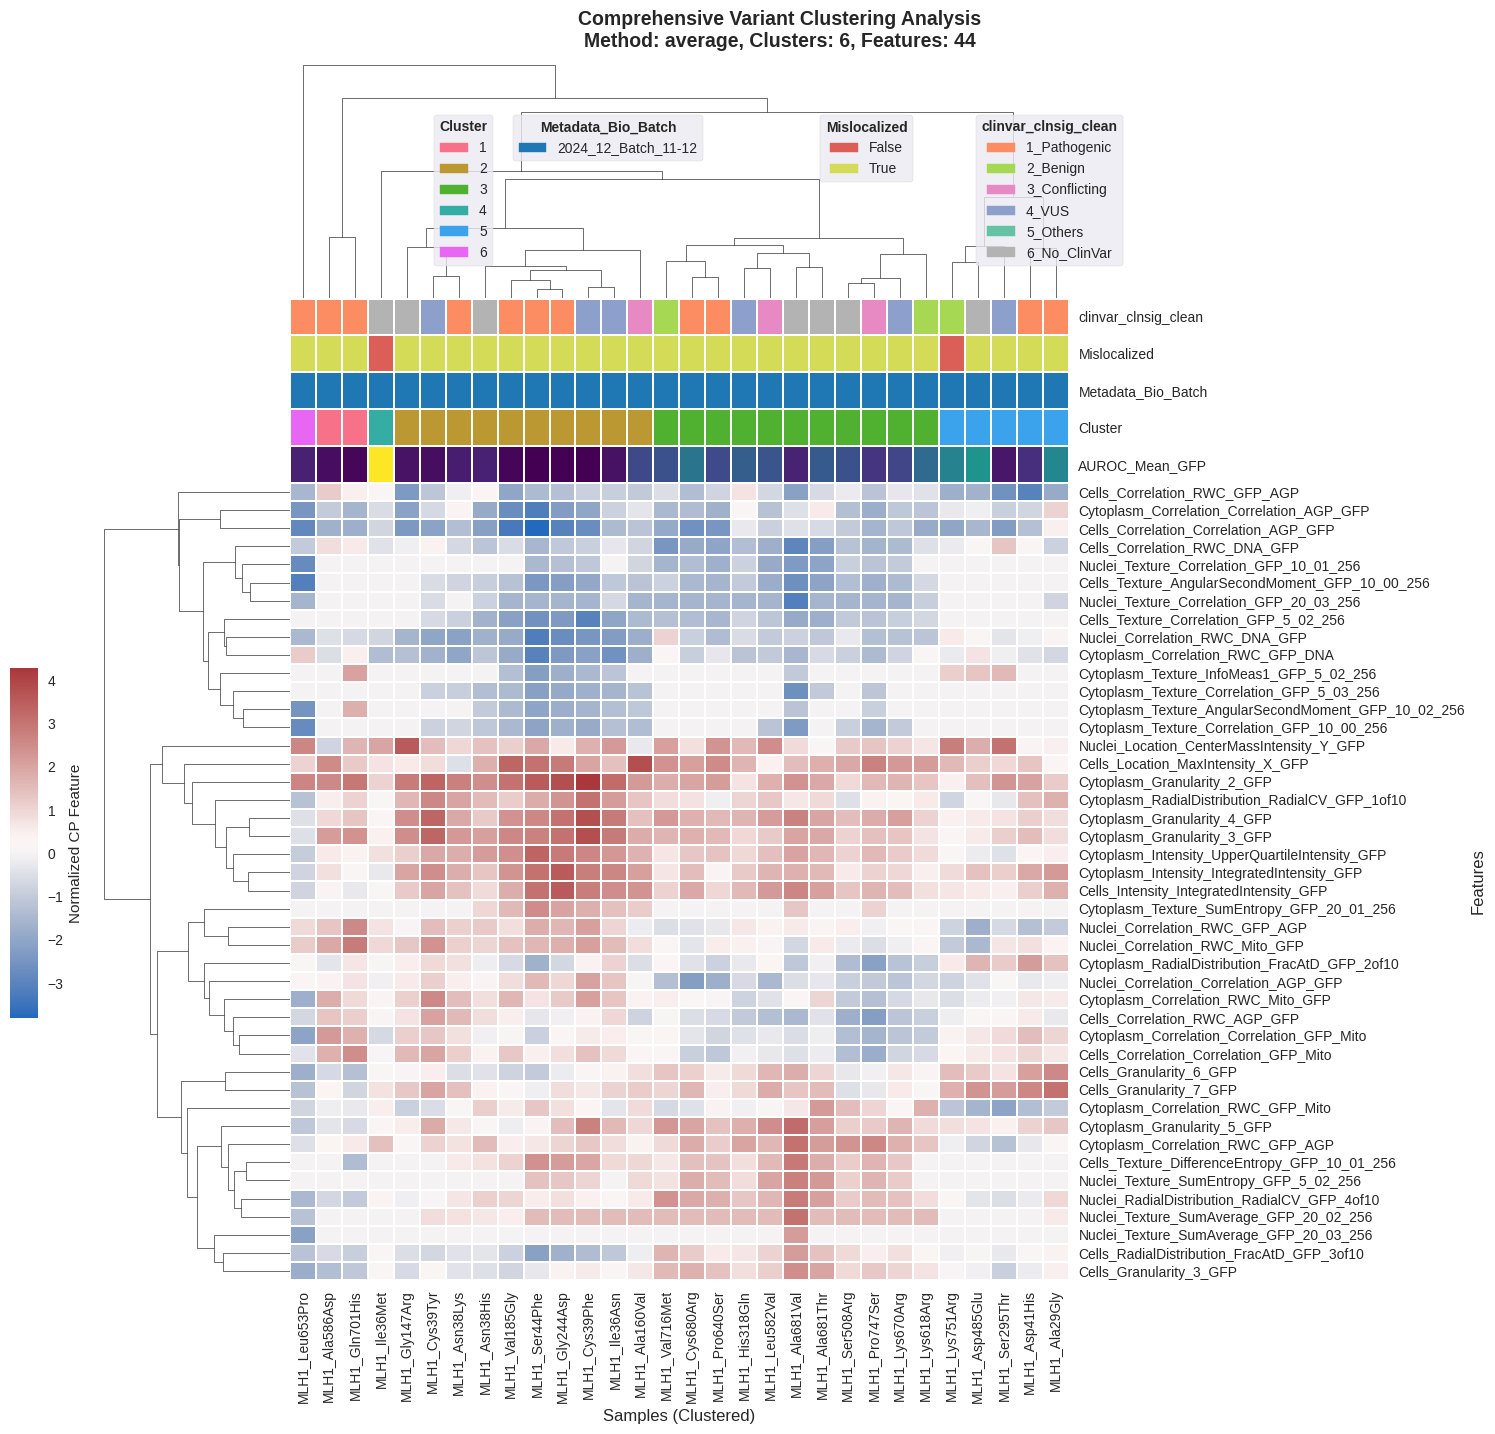

,UMAP-1,UMAP-2,Cluster,Mislocalization
Metadata_gene_allele,,,,
MLH1_Ile36Met,-0.994896,12.968250,4,False
MLH1_Asn38Lys,0.027136,11.985188,2,True
MLH1_Ala681Val,-3.132091,12.313313,3,True
MLH1_Gly147Arg,0.529418,12.536932,2,True
MLH1_Ser44Phe,-0.166125,10.448596,2,True
MLH1_Ala160Val,-1.252874,11.386803,2,True
MLH1_Leu653Pro,-1.282599,12.619988,6,True
MLH1_Cys680Arg,-3.030072,12.709470,3,True
MLH1_Lys670Arg,-2.398608,11.819765,3,True


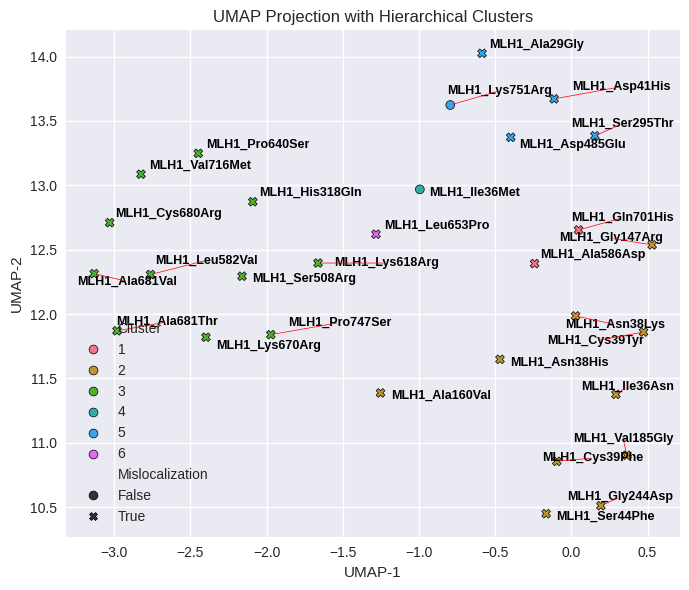

In [418]:
results = robust_cosine_clustering_with_annotations(var_allele_prof_wrt_ref_df.to_pandas().set_index("Metadata_gene_allele"),
                                                    feature_cols=[col for col in non_null_cols_batch if col in var_allele_prof_wrt_ref_df.columns],
                                                    annotation_cols=["clinvar_clnsig_clean", "Mislocalized", "Metadata_Bio_Batch"],
                                                    continuous_annotations=["AUROC_Mean_GFP"])
clustermap = create_comprehensive_clustermap(var_allele_prof_wrt_ref_df.to_pandas().set_index("Metadata_gene_allele"), 
                                             results, label="norm_wrt_cp_feat",
                                             save_path="/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP_imgs")

## 3. Protein Structure

In [376]:
import requests
import glob
import gzip
import re
import os
import numpy as np
import py3Dmol
import polars as pl
from Bio.PDB import PDBParser
from Bio.SubsMat import MatrixInfo
from sklearn.cluster import AgglomerativeClustering

In [378]:
def get_uniprot_swissprot_id(protein_name: str) -> str:
    """
    Query UniProt’s REST search API to find the reviewed (Swiss‐Prot) accession
    for a given human gene/protein name. Returns None if not found.
    """
    url = "https://rest.uniprot.org/uniprotkb/search"
    # Build a query that:
    #  - matches the gene name exactly (using “gene:”)
    #  - restricts to human (organism_id:9606)
    #  - restricts to reviewed (Swiss‐Prot) entries
    query = f"gene:{protein_name} AND organism_id:9606 AND reviewed:true"
    params = {
        "query": query,
        "fields": "accession",
        "format": "json",
        "size": 1,      # only need the top hit
    }
    try:
        resp = requests.get(url, params=params, timeout=10)
        resp.raise_for_status()
        data = resp.json()
        results = data.get("results", [])
        if not results:
            return None
        return results[0]["primaryAccession"]
    except Exception:
        # If the request fails (e.g. no internet), return None
        return None

In [419]:
gene_uniprot_id = get_uniprot_swissprot_id(gene)
print(f"UniProt Swiss‐Prot ID for {gene}:", {gene_uniprot_id} or "Not found")

af2_struc_pdb_dir = "/data/shenrunx/igvf/varchamp/2025_laval_submitted/compare_ai_scores/1_inputs/new_raw_data/alphafold/UP000005640_9606_HUMAN_v4"

pdb_file = [pdb for pdb in glob.glob(f"{af2_struc_pdb_dir}/*.pdb.gz") if gene_uniprot_id in pdb][0]
pdb_file

UniProt Swiss‐Prot ID for MLH1: {'P40692'}


'/data/shenrunx/igvf/varchamp/2025_laval_submitted/compare_ai_scores/1_inputs/new_raw_data/alphafold/UP000005640_9606_HUMAN_v4/AF-P40692-F1-model_v4.pdb.gz'

In [420]:
import pandas as pd

# 3-letter to 1-letter AA conversion dictionary
three_to_one = {
    'ALA':'A', 'ARG':'R', 'ASN':'N', 'ASP':'D', 'CYS':'C',
    'GLN':'Q', 'GLU':'E', 'GLY':'G', 'HIS':'H', 'ILE':'I',
    'LEU':'L', 'LYS':'K', 'MET':'M', 'PHE':'F', 'PRO':'P',
    'SER':'S', 'THR':'T', 'TRP':'W', 'TYR':'Y', 'VAL':'V'
}

# Load BLOSUM62 matrix from Biopython
blosum62 = MatrixInfo.blosum62

def blosum62_score(wt, mut):
    key = (wt.upper(), mut.upper())
    if key not in blosum62:
        key = (mut.upper(), wt.upper())
    return blosum62.get(key)


miyata_dist = {
    'A':{'A':0.00,'R':0.91,'N':0.83,'D':0.88,'C':1.27,'Q':0.93,'E':0.94,'G':0.60,'H':1.00,'I':1.27,'L':1.23,'K':0.99,'M':1.05,'F':1.49,'P':0.74,'S':0.58,'T':0.64,'W':1.85,'Y':1.47,'V':1.14},
    'R':{'A':0.91,'R':0.00,'N':0.77,'D':1.04,'C':1.68,'Q':0.21,'E':0.44,'G':1.27,'H':0.39,'I':1.60,'L':1.54,'K':0.25,'M':1.39,'F':1.68,'P':0.95,'S':0.87,'T':1.12,'W':1.45,'Y':1.19,'V':1.54},
    'N':{'A':0.83,'R':0.77,'N':0.00,'D':0.24,'C':1.57,'Q':0.42,'E':0.54,'G':0.80,'H':0.56,'I':1.64,'L':1.65,'K':0.80,'M':1.59,'F':1.95,'P':1.13,'S':0.26,'T':0.37,'W':2.08,'Y':1.72,'V':1.49},
    'D':{'A':0.88,'R':1.04,'N':0.24,'D':0.00,'C':1.84,'Q':0.94,'E':0.22,'G':0.89,'H':0.89,'I':1.89,'L':1.83,'K':0.89,'M':1.76,'F':2.16,'P':1.38,'S':0.50,'T':0.82,'W':2.15,'Y':1.79,'V':1.66},
    'C':{'A':1.27,'R':1.68,'N':1.57,'D':1.84,'C':0.00,'Q':1.89,'E':1.90,'G':1.70,'H':1.42,'I':1.18,'L':1.08,'K':1.89,'M':1.04,'F':1.48,'P':1.94,'S':1.16,'T':1.30,'W':1.81,'Y':1.36,'V':1.07},
    'Q':{'A':0.93,'R':0.21,'N':0.42,'D':0.94,'C':1.89,'Q':0.00,'E':0.29,'G':1.31,'H':0.45,'I':1.55,'L':1.47,'K':0.28,'M':1.24,'F':1.59,'P':1.03,'S':0.74,'T':0.90,'W':1.57,'Y':1.20,'V':1.48},
    'E':{'A':0.94,'R':0.44,'N':0.54,'D':0.22,'C':1.90,'Q':0.29,'E':0.00,'G':1.09,'H':0.73,'I':1.66,'L':1.60,'K':0.42,'M':1.44,'F':1.85,'P':1.22,'S':0.60,'T':0.86,'W':1.77,'Y':1.40,'V':1.58},
    'G':{'A':0.60,'R':1.27,'N':0.80,'D':0.89,'C':1.70,'Q':1.31,'E':1.09,'G':0.00,'H':1.40,'I':1.59,'L':1.53,'K':1.28,'M':1.50,'F':1.92,'P':0.75,'S':0.47,'T':0.58,'W':2.08,'Y':1.70,'V':1.34},
    'H':{'A':1.00,'R':0.39,'N':0.56,'D':0.89,'C':1.42,'Q':0.45,'E':0.73,'G':1.40,'H':0.00,'I':1.71,'L':1.67,'K':0.56,'M':1.52,'F':1.69,'P':1.32,'S':0.90,'T':1.06,'W':1.25,'Y':0.96,'V':1.66},
    'I':{'A':1.27,'R':1.60,'N':1.64,'D':1.89,'C':1.18,'Q':1.55,'E':1.66,'G':1.59,'H':1.71,'I':0.00,'L':0.04,'K':1.62,'M':0.16,'F':0.39,'P':1.65,'S':1.21,'T':1.04,'W':1.84,'Y':1.46,'V':0.23},
    'L':{'A':1.23,'R':1.54,'N':1.65,'D':1.83,'C':1.08,'Q':1.47,'E':1.60,'G':1.53,'H':1.67,'I':0.04,'L':0.00,'K':1.57,'M':0.22,'F':0.61,'P':1.59,'S':1.14,'T':1.01,'W':1.77,'Y':1.39,'V':0.32},
    'K':{'A':0.99,'R':0.25,'N':0.80,'D':0.89,'C':1.89,'Q':0.28,'E':0.42,'G':1.28,'H':0.56,'I':1.62,'L':1.57,'K':0.00,'M':1.41,'F':1.73,'P':1.07,'S':0.63,'T':0.83,'W':1.55,'Y':1.18,'V':1.53},
    'M':{'A':1.05,'R':1.39,'N':1.59,'D':1.76,'C':1.04,'Q':1.24,'E':1.44,'G':1.50,'H':1.52,'I':0.16,'L':0.22,'K':1.41,'M':0.00,'F':0.60,'P':1.44,'S':1.10,'T':1.03,'W':1.84,'Y':1.43,'V':0.38},
    'F':{'A':1.49,'R':1.68,'N':1.95,'D':2.16,'C':1.48,'Q':1.59,'E':1.85,'G':1.92,'H':1.69,'I':0.39,'L':0.61,'K':1.73,'M':0.60,'F':0.00,'P':1.90,'S':1.56,'T':1.57,'W':1.28,'Y':0.38,'V':0.67},
    'P':{'A':0.74,'R':0.95,'N':1.13,'D':1.38,'C':1.94,'Q':1.03,'E':1.22,'G':0.75,'H':1.32,'I':1.65,'L':1.59,'K':1.07,'M':1.44,'F':1.90,'P':0.00,'S':0.75,'T':0.76,'W':2.19,'Y':1.76,'V':1.34},
    'S':{'A':0.58,'R':0.87,'N':0.26,'D':0.50,'C':1.16,'Q':0.74,'E':0.60,'G':0.47,'H':0.90,'I':1.21,'L':1.14,'K':0.63,'M':1.10,'F':1.56,'P':0.75,'S':0.00,'T':0.17,'W':1.88,'Y':1.53,'V':1.07},
    'T':{'A':0.64,'R':1.12,'N':0.37,'D':0.82,'C':1.30,'Q':0.90,'E':0.86,'G':0.58,'H':1.06,'I':1.04,'L':1.01,'K':0.83,'M':1.03,'F':1.57,'P':0.76,'S':0.17,'T':0.00,'W':1.92,'Y':1.56,'V':0.90},
    'W':{'A':1.85,'R':1.45,'N':2.08,'D':2.15,'C':1.81,'Q':1.57,'E':1.77,'G':2.08,'H':1.25,'I':1.84,'L':1.77,'K':1.55,'M':1.84,'F':1.28,'P':2.19,'S':1.88,'T':1.92,'W':0.00,'Y':0.58,'V':1.64},
    'Y':{'A':1.47,'R':1.19,'N':1.72,'D':1.79,'C':1.36,'Q':1.20,'E':1.40,'G':1.70,'H':0.96,'I':1.46,'L':1.39,'K':1.18,'M':1.43,'F':0.38,'P':1.76,'S':1.53,'T':1.56,'W':0.58,'Y':0.00,'V':1.26},
    'V':{'A':1.14,'R':1.54,'N':1.49,'D':1.66,'C':1.07,'Q':1.48,'E':1.58,'G':1.34,'H':1.66,'I':0.23,'L':0.32,'K':1.53,'M':0.38,'F':0.67,'P':1.34,'S':1.07,'T':0.90,'W':1.64,'Y':1.26,'V':0.00}
}

# max_dist = max(max(row.values()) for row in miyata_dist.values())
def miyata_score(wt, mut):
    wt = wt.upper()
    mut = mut.upper()
    if wt not in miyata_dist or mut not in miyata_dist[wt]:
        return None  # Unknown AA
    dist = miyata_dist[wt][mut]
    # Convert distance to similarity (higher score = more similar)
    return dist

In [421]:
# 1. Parse the structure
# 1) Open the .pdb.gz file with gzip.open in text/binary mode:
with gzip.open(pdb_file, "rt") as handle:
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("rho", handle)

    # 3. Rewind and read the entire PDB text
    handle.seek(0)
    pdb_text = handle.read()

# 2. Build a map: residue_number → (x, y, z) of its Cα atom
ca_coords = {}
for model in structure:
    for chain in model:
        if chain.get_id() == "A":
            for residue in chain:
                resnum = residue.get_id()[1]
                # Only consider standard amino acids with a CA atom
                if 'CA' in residue:
                    atom_ca = residue['CA']
                    ca_coords[resnum] = atom_ca.get_coord()

# 2) List of variants in “RHO_AminoAcidResidueNumberNewAminoAcid” format.
#    We assume that the PDB’s residue numbering matches exactly the numbers in these strings.
variants_raw_list = variant_list
# 3) The chain ID in the PDB that contains Rhodopsin.
#    If your PDB uses a different chain (e.g. “B”), adjust accordingly.
chain_id = "A"
# 4) If your PDB has insertion codes (e.g. 106A, 106B), you must handle that.
#    In this example, we assume no insertion codes (icode = " ").
default_icode = " "
# Confirm chain exists
model = structure[0]  # first (and usually only) model
if chain_id not in model:
    raise ValueError(f"Chain '{chain_id}' not found in {pdb_file}.")
# ---- STEP 2: Convert each raw‐string into (chain, resi, icode, label) ----
variant_list_pdb = []
pattern = re.compile(rf"{gene}_([A-Za-z]{{3}})(\d+)([A-Za-z]{{3}})")
for raw in variants_raw_list:
    m = pattern.match(raw)
    if not m:
        print(f"Warning: '{raw}' does not match expected pattern 'RHO_Aaa###Bbb'. Skipping.")
        continue
    wt_3letter, resi_str, mut_3letter = m.groups()
    resi = int(resi_str)
    
    # Residue-by-residue QC: check if residue exists and matches wild-type in PDB
    residue = None
    for model in structure:
        chain = model[chain_id]
        # Residue id: usually (' ', resi, ' ')
        res_id = (' ', resi, ' ')
        if res_id in chain:
            residue = chain[res_id]
            break

    if residue is None:
        print(f"Warning: residue number {resi} not found in chain {chain_id} in PDB. Skipping variant {raw}.")
        continue

    pdb_resname = residue.get_resname()  # 3-letter code from PDB
    if pdb_resname.upper() != wt_3letter.upper():
        print(f"Warning: residue mismatch at position {resi} for variant {raw}: "
              f"PDB has {pdb_resname}, variant expects {wt_3letter}. Skipping.")
        continue

    # Convert 3-letter to 1-letter
    wt_1letter = three_to_one.get(wt_3letter.upper(), "X")
    mut_1letter = three_to_one.get(mut_3letter.upper(), "X")

    # Calculate scores
    blosum_score = blosum62_score(wt_1letter, mut_1letter)
    miyata_sim = miyata_score(wt_1letter, mut_1letter)
    
    # Convert three‐letter codes to one‐letter for a concise label if you like.
    # Here, we'll keep the original string as the label.
    label = raw
    variant_list_pdb.append({
        "chain": chain_id,
        "resi": resi,
        "icode": default_icode,
        "label": label,
        "wt_aa": wt_1letter,
        "mut_aa": mut_1letter,
        "blosum62_score": blosum_score,
        "miyata_score": miyata_sim
    })

print(variant_list_pdb)
if not variant_list_pdb:
    raise RuntimeError("No valid variants found. Please check your variant strings.")

[{'chain': 'A', 'resi': 36, 'icode': ' ', 'label': 'MLH1_Ile36Met', 'wt_aa': 'I', 'mut_aa': 'M', 'blosum62_score': 1, 'miyata_score': 0.16}, {'chain': 'A', 'resi': 38, 'icode': ' ', 'label': 'MLH1_Asn38Lys', 'wt_aa': 'N', 'mut_aa': 'K', 'blosum62_score': 0, 'miyata_score': 0.8}, {'chain': 'A', 'resi': 681, 'icode': ' ', 'label': 'MLH1_Ala681Val', 'wt_aa': 'A', 'mut_aa': 'V', 'blosum62_score': 0, 'miyata_score': 1.14}, {'chain': 'A', 'resi': 147, 'icode': ' ', 'label': 'MLH1_Gly147Arg', 'wt_aa': 'G', 'mut_aa': 'R', 'blosum62_score': -2, 'miyata_score': 1.27}, {'chain': 'A', 'resi': 44, 'icode': ' ', 'label': 'MLH1_Ser44Phe', 'wt_aa': 'S', 'mut_aa': 'F', 'blosum62_score': -2, 'miyata_score': 1.56}, {'chain': 'A', 'resi': 160, 'icode': ' ', 'label': 'MLH1_Ala160Val', 'wt_aa': 'A', 'mut_aa': 'V', 'blosum62_score': 0, 'miyata_score': 1.14}, {'chain': 'A', 'resi': 653, 'icode': ' ', 'label': 'MLH1_Leu653Pro', 'wt_aa': 'L', 'mut_aa': 'P', 'blosum62_score': -3, 'miyata_score': 1.59}, {'chain':

In [422]:
misloc_alleles = imaging_summary.filter((pl.col("Altered_95th_perc_GFP")==1)&(pl.col("gene_allele").str.contains(gene)))["gene_allele"].unique()

In [423]:
# sns.displot(
#     data=imaging_summary_clinvar.filter((pl.col("gene_allele").str.contains(gene))).select([ ##(pl.col("Altered_95th_perc_GFP")==1)&
#         "gene_allele",
#         "AUROC_Mean_GFP",
#         'ESM1b_score',
#         'ESM1b_rankscore',
#         'ESM1b_pred',
#         'AlphaMissense_score',
#         'AlphaMissense_rankscore',
#         'AlphaMissense_pred']
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="ESM1b_pred",
#     kind="hist",
#     common_norm=False
# )

In [424]:
pl.DataFrame(variant_list_pdb).filter(pl.col("label").is_in(misloc_alleles))

chain,resi,icode,label,wt_aa,mut_aa,blosum62_score,miyata_score
str,i64,str,str,str,str,i64,f64
"""A""",38,""" ""","""MLH1_Asn38Lys""","""N""","""K""",0,0.8
"""A""",681,""" ""","""MLH1_Ala681Val""","""A""","""V""",0,1.14
"""A""",147,""" ""","""MLH1_Gly147Arg""","""G""","""R""",-2,1.27
"""A""",44,""" ""","""MLH1_Ser44Phe""","""S""","""F""",-2,1.56
"""A""",160,""" ""","""MLH1_Ala160Val""","""A""","""V""",0,1.14
…,…,…,…,…,…,…,…
"""A""",244,""" ""","""MLH1_Gly244Asp""","""G""","""D""",-1,0.89
"""A""",318,""" ""","""MLH1_His318Gln""","""H""","""Q""",0,0.45
"""A""",582,""" ""","""MLH1_Leu582Val""","""L""","""V""",1,0.32


In [425]:
# Define 3D offsets for each residue
offsets_3d = {
    135: {'x': +1.0, 'y': +0.5, 'z': +0.5},
    110: {'x': -1.0, 'y': +0.5, 'z': +0.5},
    190: {'x':  0.0, 'y': -1.0, 'z': +0.5}
}

view = py3Dmol.view(width=800, height=600)
view.addModel(pdb_text, 'pdb')
view.setStyle({'cartoon': {'color': 'spectrum'}})

residues_to_label = [var['resi'] for var in variant_list_pdb]
# Get atom coordinates first to calculate proper offsets
for i, residue_info in enumerate(variant_list_pdb):
    resi = residue_info["resi"]
    color = 'red' if residue_info["label"] in misloc_alleles else 'blue'
    view.setStyle({'chain': 'A', 'resi': resi, 'atom': 'CA'}, {'sphere': {'color': color, 'radius': 0.9}})
    view.addResLabels({'chain': 'A', 'resi': resi}, 
                      {'fontColor': 'red' if color == 'red' else 'white', 'fontSize': 15, 'showBg': False})
    
view.zoomTo()
view.show()

# Save the interactive view as standalone HTML
html_content = view._make_html()
with open(f'protein_viewer_{gene}.html', 'w') as f:
    f.write(html_content)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.